In [1]:
# =========================
# Standard libraries
# =========================
import os
import json
import random
import pickle
import warnings
import math
import re

from datetime import datetime

warnings.filterwarnings("ignore")


# =========================
# Data processing
# =========================
import numpy as np
import pandas as pd



# =========================
# Visualization
# =========================
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors

from matplotlib import cm
from matplotlib.colors import (
    LinearSegmentedColormap,
    BoundaryNorm,
    Normalize,
)
from matplotlib.colorbar import ColorbarBase
from mpl_toolkits.axes_grid1 import make_axes_locatable



# =========================
# Display settings
# =========================
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": [
        "Times New Roman",   # Prefer if installed
        "Liberation Serif",  # Common on Ubuntu / Debian
        "Nimbus Roman",      # Common with TeX / Ghostscript
        "DejaVu Serif"       # Matplotlib fallback
    ],
    "mathtext.fontset": "stix",       # Math symbols closer to Times
    "axes.unicode_minus": False,
})

pd.set_option("display.max_columns", None)

# ExperimentFirst — z_a reconstruction lab (norm space)

Phase 1 goal: **`data_f` → encoder → `z_a` → decoder → `â` ≈ `data_f`**.

- Preprocess builds `data_f` + soft `weight` (edit `filter_threshold`, `filter_gamma` in preprocess cells).
- Train AE; metrics measure **how much of `data_f` is preserved in `z_a`** via decoder reconstruction.
- No `tau_pred` / sparse hard gate — model output is **`â = p_hat × v_hat`** (`outputs["a_hat"]`).
- Full pipeline: `bash SynEnergy/Bash/DiffusionTS/run_controlnet_train.sh`


In [3]:
# === ControlNet-aligned setup (norm space, backbone normalizer) ===
import sys
from pathlib import Path

ANALYSIS_DIR = Path(".").resolve()
SYNENERGY_ROOT = (ANALYSIS_DIR / ".." / "SynEnergy").resolve()
sys.path.insert(0, str(SYNENERGY_ROOT))

from Utils.io_utils import load_yaml_config
from Data.build_dataloader import load_normalizer_from_disk
from controlnet.ae.residual_learner import (
    extract_standardized_residual,
    filter_residual_deviation,
    occurrence_mask_from_data_r,
    build_ae_cfg,
    train_zero_aware_autoencoder,
    extract_anomaly_latent,
    ZeroAwareResidualAutoencoder,
    ResidualDataset,
)

CONTROLNET_CONFIG = load_yaml_config(str(SYNENERGY_ROOT / "Config/Extreme/power_controlnet_temporal.yaml"))
CN_CFG = CONTROLNET_CONFIG["controlnet"]
BACKBONE_OUTPUT = SYNENERGY_ROOT / "OUTPUT" / "power" / "diffusionts" / "power1"   

DATA_PATH = SYNENERGY_ROOT / CONTROLNET_CONFIG["train"]["params"]["data_path"]
COND_PATH = SYNENERGY_ROOT / CONTROLNET_CONFIG["train"]["params"]["cond_path"]

data_raw = np.load(DATA_PATH).astype(np.float32)
normalizer = load_normalizer_from_disk(str(BACKBONE_OUTPUT))
if normalizer is None:
    raise FileNotFoundError(
        f"Train backbone first: {BACKBONE_OUTPUT / 'normalizer.joblib'}"
    )

flat = data_raw.reshape(-1, data_raw.shape[-1])
data = normalizer.normalize(flat).reshape(data_raw.shape).astype(np.float32)

print(f"data_raw: {data_raw.shape}, norm data: {data.shape}, range [{data.min():.3f}, {data.max():.3f}]")
print(f"normalizer: {BACKBONE_OUTPUT / 'normalizer.joblib'}")
print("Next: preprocess cells — explicit filter_threshold / occurrence_threshold / filter_gamma.")


data_raw: (10000, 180, 1), norm data: (10000, 180, 1), range [-1.000, 1.000]
normalizer: /home/ec2-user/project/Energy/SysEnergy/SynEnergy/OUTPUT/power/diffusionts/power1/normalizer.joblib
Next: preprocess cells — explicit filter_threshold / occurrence_threshold / filter_gamma.


In [4]:
data_r, baseline, scale, raw_residual, mad = extract_standardized_residual(
    data,
    num_days=30,
    slots_per_day=6,
    min_scale=1.0,
    use_mad_consistency=True,
)


In [5]:
import numpy as np
import matplotlib.pyplot as plt
def plot_original_and_residual(
    data,
    standardized_residual,
    n_samples=10,
    random_state=None,
    slots_per_day=6,
    num_days=30,
    figsize=(14, 8),
    alpha=0.7,
    lw=1.0,
):
    """
    上下对比图：上为原始负荷，下为标准化残差。
    从 N 个用户中随机抽取 n_samples 条曲线叠加绘制。
    Parameters
    ----------
    data : np.ndarray, shape (N, 180, 1)
    standardized_residual : np.ndarray, shape (N, 180, 1)
    n_samples : int
        随机抽取的用户数，默认 10。
    random_state : int or None
        随机种子，便于复现。
    slots_per_day : int
        每天时间点数，用于画日界分隔线，默认 6。
    num_days : int
        天数，默认 30。
    """
    # ---------- shape check ----------
    if data.shape != standardized_residual.shape:
        raise ValueError(
            f"shape mismatch: data {data.shape} vs residual {standardized_residual.shape}"
        )
    n_users, time_len, n_features = data.shape
    expected_len = num_days * slots_per_day
    if time_len != expected_len or n_features != 1:
        raise ValueError(
            f"expected shape (N, {expected_len}, 1), got {data.shape}"
        )
    if n_samples > n_users:
        raise ValueError(f"n_samples={n_samples} > n_users={n_users}")
    # ---------- random sample ----------
    rng = np.random.default_rng(random_state)
    idx = rng.choice(n_users, size=n_samples, replace=False)
    # squeeze 最后一维 -> (n_samples, 180)
    orig = data[idx, :, 0]
    resid = standardized_residual[idx, :, 0]
    x = np.arange(time_len)
    # ---------- plot ----------
    fig, axes = plt.subplots(2, 1, figsize=figsize, sharex=True)
    cmap = plt.cm.tab10  # 最多 10 种颜色，与 n_samples=10 匹配
    for k in range(n_samples):
        color = cmap(k % 10)
        axes[0].plot(x, orig[k], color=color, alpha=alpha, lw=lw, label=f"user {idx[k]}")
        axes[1].plot(x, resid[k], color=color, alpha=alpha, lw=lw, label=f"user {idx[k]}")
    # 每天分隔线（每 6 个点一条）
    for d in range(1, num_days):
        axes[0].axvline(d * slots_per_day - 0.5, color="gray", lw=0.5, alpha=0.3)
        axes[1].axvline(d * slots_per_day - 0.5, color="gray", lw=0.5, alpha=0.3)
    axes[0].set_title(f"Original load — random {n_samples} users")
    axes[0].set_ylabel("Load")
    axes[0].grid(True, alpha=0.25)
    axes[1].set_title(f"Standardized residual — same {n_samples} users")
    axes[1].set_ylabel("Residual")
    axes[1].axhline(0, color="black", lw=0.8, alpha=0.5)  # 残差零线
    axes[1].grid(True, alpha=0.25)
    axes[1].set_xlabel(f"Time index (0–{time_len - 1}, {num_days} days × {slots_per_day} slots/day)")
    # 图例放在右侧外侧，避免遮挡曲线
    axes[0].legend(
        loc="upper left",
        bbox_to_anchor=(1.01, 1),
        fontsize=8,
        frameon=False,
    )
    plt.tight_layout()
    plt.show()
    return fig, axes, idx  # 返回抽中的用户索引，方便后续核对


def plot_anomaly_pack_sample(
    data,
    data_r,
    data_f,
    weight,
    mask,
    sample_idx=None,
    random_state=None,
    slots_per_day=6,
    num_days=30,
    figsize=(14, 12),
    lw=1.2,
):
    """
    随机抽同一条样本，5×1 对比：
      1. data   — 原始负荷
      2. data_r — 标准化残差（MAD per-user）
      3. data_f — soft 过滤后的 signed 残差
      4. weight — soft gate 权重 ∈ [0, 1]
      5. mask   — binary occurrence（|data_r| > τ，评估用）

    Parameters
    ----------
    data, data_r, data_f, weight, mask : np.ndarray, shape (N, T, 1)
    sample_idx : int or None
        指定样本索引；None 时随机抽取。
    random_state : int or None
        随机种子（仅 sample_idx=None 时生效）。
    """
    arrays = {
        "data": data,
        "data_r": data_r,
        "data_f": data_f,
        "weight": weight,
        "mask": mask,
    }
    ref_shape = None
    for name, arr in arrays.items():
        arr = np.asarray(arr)
        if arr.ndim != 3 or arr.shape[-1] != 1:
            raise ValueError(f"{name} must have shape (N, T, 1), got {arr.shape}")
        if ref_shape is None:
            ref_shape = arr.shape
        elif arr.shape != ref_shape:
            raise ValueError(
                f"shape mismatch: {name} {arr.shape} vs expected {ref_shape}"
            )

    n_users, time_len, _ = ref_shape
    expected_len = num_days * slots_per_day
    if time_len != expected_len:
        raise ValueError(
            f"expected T={expected_len} ({num_days}×{slots_per_day}), got {time_len}"
        )

    if sample_idx is None:
        rng = np.random.default_rng(random_state)
        sample_idx = int(rng.integers(0, n_users))
    else:
        sample_idx = int(sample_idx)
        if not (0 <= sample_idx < n_users):
            raise ValueError(f"sample_idx={sample_idx} out of range [0, {n_users})")

    y_data = data[sample_idx, :, 0]
    y_data_r = data_r[sample_idx, :, 0]
    y_data_f = data_f[sample_idx, :, 0]
    y_weight = weight[sample_idx, :, 0]
    y_mask = mask[sample_idx, :, 0]
    x = np.arange(time_len)

    panels = [
        ("Original load (data)", y_data, "Load", None),
        ("Standardized residual (data_r)", y_data_r, "data_r", 0.0),
        ("Filtered residual (data_f)", y_data_f, "data_f", 0.0),
        ("Soft gate (weight)", y_weight, "weight", None),
        ("Binary occurrence (mask_hard)", y_mask, "mask", None),
    ]

    fig, axes = plt.subplots(5, 1, figsize=figsize, sharex=True)

    for ax, (title, y, ylabel, hline) in zip(axes, panels):
        ax.plot(x, y, color="C0", lw=lw)
        if hline is not None:
            ax.axhline(hline, color="black", lw=0.8, alpha=0.5)
        if "weight" in title or "Binary" in title:
            ax.set_ylim(-0.05, 1.05)
        for d in range(1, num_days):
            ax.axvline(d * slots_per_day - 0.5, color="gray", lw=0.5, alpha=0.3)
        ax.set_title(f"{title} — sample {sample_idx}")
        ax.set_ylabel(ylabel)
        ax.grid(True, alpha=0.25)

    axes[-1].set_xlabel(
        f"Time index (0–{time_len - 1}, {num_days} days × {slots_per_day} slots/day)"
    )
    fig.suptitle(f"Anomaly pack (same sample idx={sample_idx})", y=1.01)
    plt.tight_layout()
    plt.show()
    return fig, axes, sample_idx

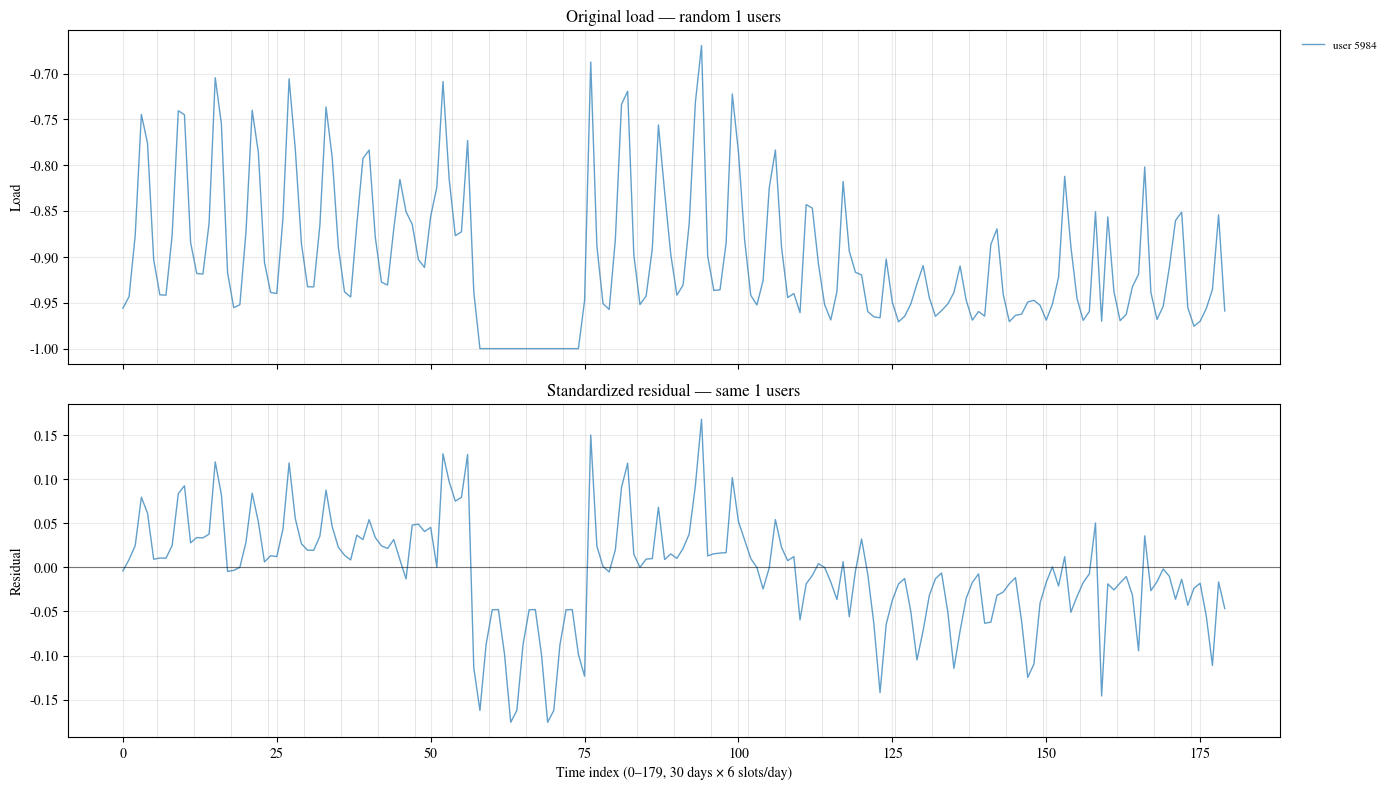

In [6]:
fig, axes, sampled_idx = plot_original_and_residual(
    data,
    data_r,
    n_samples=1,
    random_state=np.random.randint(0, 10000),
)

## Preprocess pipeline (explicit steps)

Build **`data_f`** (AE target) and soft **`weight`** (encoder input + loss weights).

1. `extract_standardized_residual(data)` → `data_r`
2. `filter_residual_deviation(data_r, filter_threshold, gamma)` → `data_f`, `weight`
3. `occurrence_mask_from_data_r` → `mask_hard` (optional viz / probe stats only; **not** used in reconstruction metrics)


In [7]:
# === Tunable preprocess params (edit here) ===
# filter_threshold = 0.1        # soft sigmoid center τ  → weight, data_f
# occurrence_threshold = 0.1    # hard GT τ_occ          → mask_hard
# filter_mode = CN_CFG.get("filter_mode", "soft")
# filter_gamma = float(CN_CFG.get("filter_gamma", 5.0))

RESIDUAL_KW = dict(
    num_days=int(CN_CFG.get("num_days", 30)),
    slots_per_day=int(CN_CFG.get("slots_per_day", 6)),
    eps=float(CN_CFG.get("residual_eps", 1e-6)),
    min_scale=float(CN_CFG.get("min_scale", 1.0)),
    use_mad_consistency=bool(CN_CFG.get("use_mad_consistency", True)),
)

# Step 1: standardized residual
data_r, baseline, scale, raw_residual, mad = extract_standardized_residual(
    data,
    **RESIDUAL_KW,
)
print(f"data_r: shape={data_r.shape}, range=[{data_r.min():.3f}, {data_r.max():.3f}]")


data_r: shape=(10000, 180, 1), range=[-1.778, 1.721]


In [8]:
# === Step 2: gamma sweep at fixed threshold (soft gate diagnostics) ===
SWEEP_THRESHOLD = 0.1  # fixed τ; mask_hard depends only on τ, not γ

GAMMA_SWEEP = [1.0, 2.0, 5.0, 10.0, 15.0, 20.0, 30.0, 50.0, 75.0, 100.0]

filter_mode = "soft"

abs_r = np.abs(data_r)
frac_below = float((abs_r < SWEEP_THRESHOLD).mean())
print(
    f"|data_r|: median={np.median(abs_r):.4f}, q90={np.quantile(abs_r, 0.9):.4f}, "
    f"frac<{SWEEP_THRESHOLD}={frac_below:.1%}"
)

sweep_rows = []
for g in GAMMA_SWEEP:
    mh = occurrence_mask_from_data_r(data_r, threshold=float(SWEEP_THRESHOLD))
    data_f_sw, w = filter_residual_deviation(
        data_r,
        threshold=float(SWEEP_THRESHOLD),
        mode=filter_mode,
        gamma=float(g),
    )
    ratio = np.abs(data_f_sw) / (abs_r + 1e-8)
    below = abs_r < SWEEP_THRESHOLD
    above = ~below
    sweep_rows.append({
        "gamma": float(g),
        "threshold": float(SWEEP_THRESHOLD),
        "mask_hard_rate": float(mh.mean()),
        "weight_mean": float(w.mean()),
        "weight_std": float(w.std()),
        "weight_min": float(w.min()),
        "weight_p50": float(np.median(w)),
        "weight_p90": float(np.quantile(w, 0.9)),
        "weight_max": float(w.max()),
        "data_f_over_data_r": float(ratio.mean()),
        "weight_below_tau": float(w[below].mean()) if below.any() else np.nan,
        "weight_above_tau": float(w[above].mean()) if above.any() else np.nan,
    })

sweep_df = pd.DataFrame(sweep_rows)
display(sweep_df)

# weight_std ↑ and data_f_over_data_r ↓ → soft filter actually separating when gamma is large


|data_r|: median=0.0262, q90=0.1128, frac<0.1=87.6%


,gamma,threshold,mask_hard_rate,weight_mean,weight_std,weight_min,weight_p50,weight_p90,weight_max,data_f_over_data_r,weight_below_tau,weight_above_tau
0,1.0,0.1,0.124269,0.486578,0.015563,0.475021,0.481547,0.503209,0.842705,0.482969,0.482173,0.517619
1,2.0,0.1,0.124269,0.473130,0.030278,0.450166,0.463144,0.506417,0.966333,0.469710,0.464407,0.534599
2,5.0,0.1,0.124269,0.432967,0.069639,0.377541,0.408728,0.516038,0.999773,0.430099,0.412069,0.580243
3,10.0,0.1,0.124269,0.369597,0.123964,0.268941,0.323342,0.532043,1.000000,0.367554,0.331117,0.640771
4,15.0,0.1,0.124269,0.314640,0.166521,0.182426,0.248303,0.547982,1.000000,0.313254,0.261826,0.686820
5,20.0,0.1,0.124269,0.270023,0.198861,0.119203,0.185894,0.563823,1.000000,0.269118,0.205784,0.722719
6,30.0,0.1,0.124269,0.209288,0.240595,0.047426,0.098379,0.595088,1.000000,0.208927,0.129046,0.774752
7,50.0,0.1,0.124269,0.156843,0.277005,0.006693,0.024309,0.655144,1.000000,0.156792,0.060398,0.836496
8,75.0,0.1,0.124269,0.137704,0.293902,0.000553,0.003917,0.723641,1.000000,0.137700,0.032614,0.878282
9,100.0,0.1,0.124269,0.131449,0.302105,0.000045,0.000620,0.783038,1.000000,0.131449,0.021958,0.903039


In [9]:
# === Step 3: apply chosen threshold ===
filter_threshold = 0.12
occurrence_threshold = 0.12
mask_hard = occurrence_mask_from_data_r(data_r, threshold=float(occurrence_threshold))
filter_gamma = 50
data_f, weight = filter_residual_deviation(
    data_r,
    threshold=float(filter_threshold),
    mode=filter_mode,
    gamma=filter_gamma,
)
mask = weight
preprocess_threshold = filter_threshold  # alias for eval / summary cells below

print(
    f"filter_threshold={filter_threshold}, occurrence_threshold={occurrence_threshold}, "
    f"filter_mode={filter_mode}, filter_gamma={filter_gamma}"
)
print(f"weight mean={weight.mean():.6f}, mask_hard rate={mask_hard.mean():.6f}")
print("Target mask_hard rate ~5%-15%. Then sync yaml: controlnet.filter_threshold / occurrence_threshold.")

# SynEnergy/Config/Extreme/power_controlnet.yaml


filter_threshold=0.12, occurrence_threshold=0.12, filter_mode=soft, filter_gamma=50
weight mean=0.110641, mask_hard rate=0.088797
Target mask_hard rate ~5%-15%. Then sync yaml: controlnet.filter_threshold / occurrence_threshold.


In [10]:
import numpy as np
import pandas as pd
# 假设已有 data_r，shape = (N, T, 1)
abs_r = np.abs(data_r).ravel()
target_rates = [0.01, 0.05, 0.10, 0.15, 0.20]
rows = []
for p in target_rates:
    # 让 top p% 的 |data_r| 超过 threshold
    thr = np.percentile(abs_r, 100 * (1 - p))
    actual_rate = (abs_r > thr).mean()
    rows.append({
        "target_rate_%": f"{p*100:.0f}%",
        "threshold": thr,
        "actual_rate_%": f"{actual_rate*100:.4f}%",
        "actual_rate": actual_rate,
    })
df_threshold_table = pd.DataFrame(rows)
df_threshold_table

,target_rate_%,threshold,actual_rate_%,actual_rate
0,1%,0.279080,0.9991%,0.009991
1,5%,0.156024,4.9978%,0.049978
2,10%,0.112835,9.9938%,0.099938
3,15%,0.089185,14.9911%,0.149911
4,20%,0.073052,19.9961%,0.199961


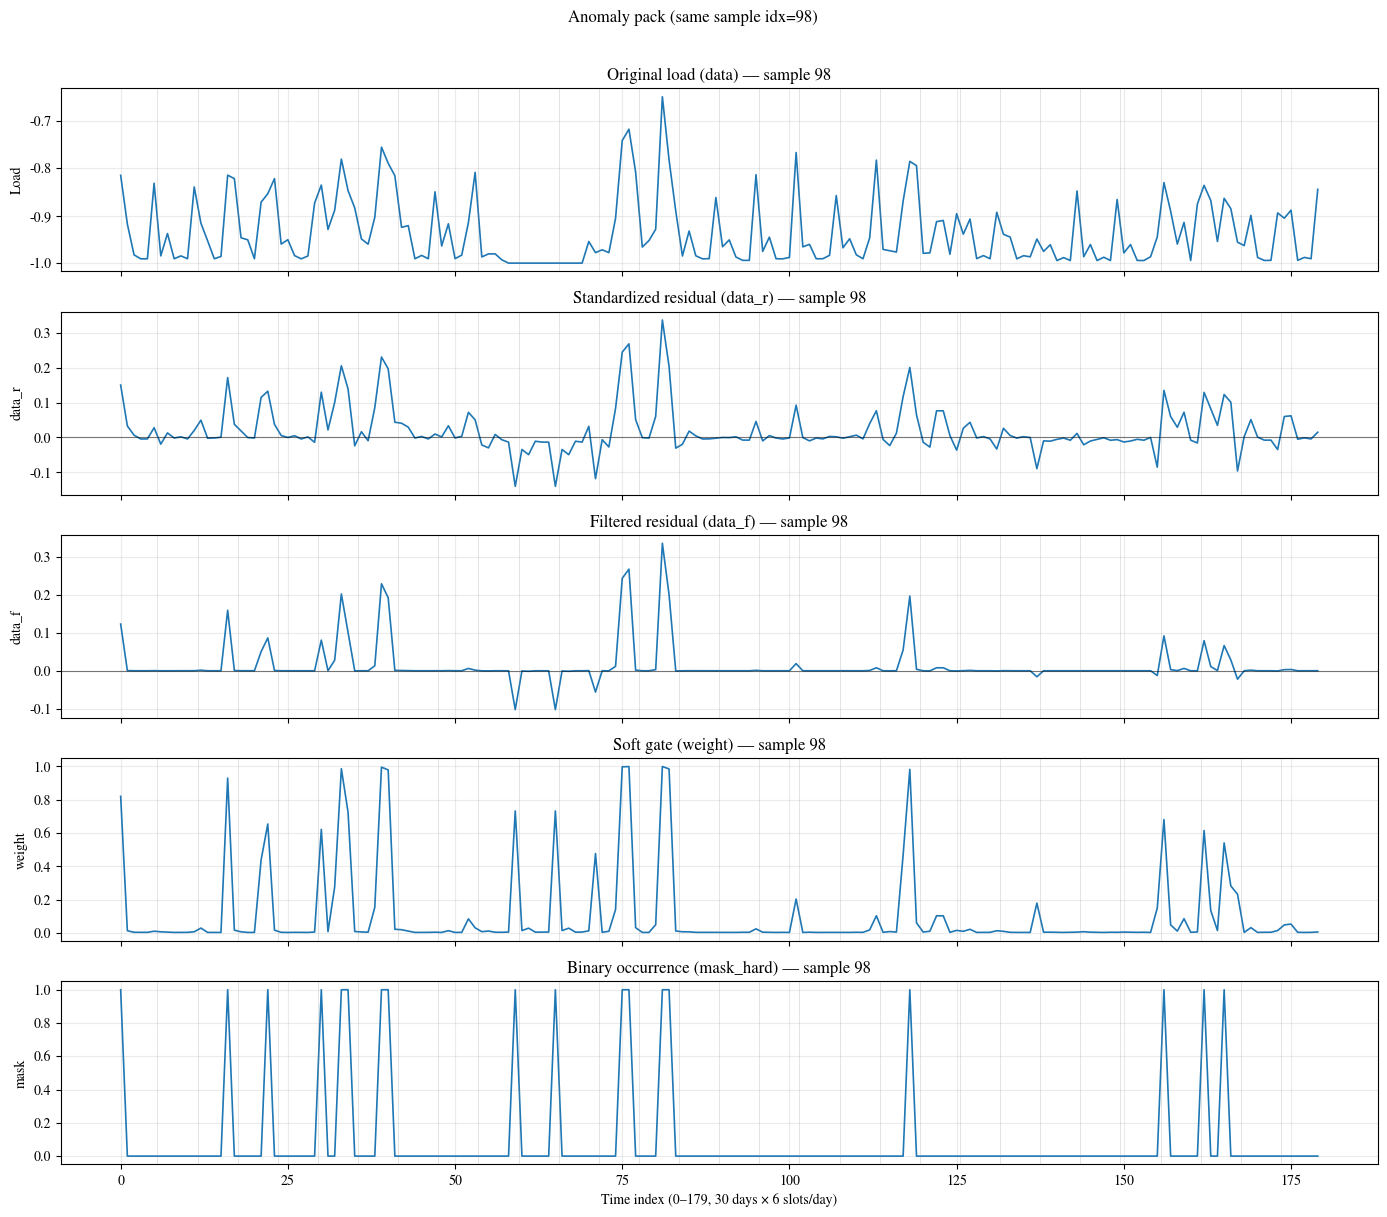

sampled_idx=98


In [10]:
fig, axes, sampled_idx = plot_anomaly_pack_sample(
    data,
    data_r,
    data_f,
    weight,
    mask_hard,
    random_state=np.random.randint(0, 10000),
)
print(f"sampled_idx={sampled_idx}")

In [59]:
# ZeroAwareResidualAutoencoder — imported from controlnet (no duplicate definition)
from controlnet.ae.residual_learner import ZeroAwareResidualAutoencoder, ResidualDataset
print("Using", ZeroAwareResidualAutoencoder.__module__ + "." + ZeroAwareResidualAutoencoder.__name__)


Using controlnet.ae.residual_learner.ZeroAwareResidualAutoencoder


In [60]:
"""
Pipeline (reconstruction-centric):

1. data_f  — soft-filtered signed residual (AE training target)
2. weight  — soft gate from preprocess (encoder input + loss weighting)
3. encode: [data_f, weight, cond] → z_a
4. decode: z_a → p_hat, v_hat → â = p_hat * v_hat   ← evaluate this vs data_f
5. loss: weighted MSE on â vs data_f (anom + zero regions)
6. z_a quality: reconstruction metrics + shuffle-z test + latent probes
"""


'\nPipeline (reconstruction-centric):\n\n1. data_f  — soft-filtered signed residual (AE training target)\n2. weight  — soft gate from preprocess (encoder input + loss weighting)\n3. encode: [data_f, weight, cond] → z_a\n4. decode: z_a → p_hat, v_hat → â = p_hat * v_hat   ← evaluate this vs data_f\n5. loss: weighted MSE on â vs data_f (anom + zero regions)\n6. z_a quality: reconstruction metrics + shuffle-z test + latent probes\n'

In [61]:
# Pipeline (aligned with SynEnergy controlnet/)
# 1. Load data; normalize via backbone normalizer
# 2. extract_standardized_residual → data_r
# 3. occurrence_mask_from_data_r → mask_hard
# 4. filter_residual_deviation → data_f, weight
# 5. train_zero_aware_autoencoder → z_a
# 6. evaluate (soft train / hard eval)
# 7. run_controlnet_train.sh for full AE + ControlNet


In [62]:
# Evaluation helpers only — training uses controlnet.ae.residual_learner (imported in setup)
from typing import Dict, List, Optional, Union

import numpy as np
import torch
from torch.utils.data import DataLoader

from controlnet.ae.residual_learner import ZeroAwareResidualAutoencoder, ResidualDataset


@torch.no_grad()
def collect_model_outputs(
    model: ZeroAwareResidualAutoencoder,
    data_f: Union[np.ndarray, torch.Tensor],
    mask: Union[np.ndarray, torch.Tensor],
    cond: Union[np.ndarray, torch.Tensor],
    batch_size: int = 256,
    device: Optional[Union[str, torch.device]] = None,
) -> Dict[str, np.ndarray]:
    if device is None:
        device = next(model.parameters()).device
    elif not isinstance(device, torch.device):
        device = torch.device(device)

    model = model.to(device)
    model.eval()

    dataset = ResidualDataset(data_f=data_f, mask=mask, cond=cond)
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False)

    target_chunks, weight_chunks = [], []
    a_hat_chunks, p_logit_chunks, p_hat_chunks, v_hat_chunks, z_chunks = [], [], [], [], []

    for batch in loader:
        residual = batch["residual"].to(device)
        weight_b = batch["mask"].to(device)
        cond_b = batch["cond"].to(device)

        out = model(residual, weight_b, cond_b)

        target_chunks.append(residual.cpu().numpy())
        weight_chunks.append(weight_b.cpu().numpy())
        a_hat_chunks.append(out["a_hat"].cpu().numpy())
        p_logit_chunks.append(out["p_logit"].cpu().numpy())
        p_hat_chunks.append(out["p_hat"].cpu().numpy())
        v_hat_chunks.append(out["v_hat"].cpu().numpy())
        z_chunks.append(out["z_a"].cpu().numpy())

    return {
        "target": np.concatenate(target_chunks, axis=0),
        "weight": np.concatenate(weight_chunks, axis=0),
        "mask": np.concatenate(weight_chunks, axis=0),
        "a_hat": np.concatenate(a_hat_chunks, axis=0),
        "p_logit": np.concatenate(p_logit_chunks, axis=0),
        "p_hat": np.concatenate(p_hat_chunks, axis=0),
        "v_hat": np.concatenate(v_hat_chunks, axis=0),
        "z": np.concatenate(z_chunks, axis=0),
    }


@torch.no_grad()
def decoder_forward_with_given_z(
    model: ZeroAwareResidualAutoencoder,
    z: Union[np.ndarray, torch.Tensor],
    batch_size: int = 256,
    device: Optional[Union[str, torch.device]] = None,
) -> Dict[str, np.ndarray]:
    """Decoder uses z_a only (no cond). For shuffle-z test."""
    if device is None:
        device = next(model.parameters()).device
    elif not isinstance(device, torch.device):
        device = torch.device(device)

    model = model.to(device)
    model.eval()

    z_t = torch.as_tensor(z, dtype=torch.float32)
    if z_t.ndim == 3 and z_t.shape[-1] == 1:
        z_t = z_t.squeeze(-1)
    loader = DataLoader(torch.utils.data.TensorDataset(z_t), batch_size=batch_size, shuffle=False)

    a_hat_chunks, p_logit_chunks, p_hat_chunks, v_hat_chunks = [], [], [], []
    for (z_b,) in loader:
        z_b = z_b.to(device)
        a_hat_b, p_logit_b, p_hat_b, v_hat_b = model.decode(z_b)
        a_hat_chunks.append(a_hat_b.cpu().numpy())
        p_logit_chunks.append(p_logit_b.cpu().numpy())
        p_hat_chunks.append(p_hat_b.cpu().numpy())
        v_hat_chunks.append(v_hat_b.cpu().numpy())

    return {
        "a_hat": np.concatenate(a_hat_chunks, axis=0),
        "p_logit": np.concatenate(p_logit_chunks, axis=0),
        "p_hat": np.concatenate(p_hat_chunks, axis=0),
        "v_hat": np.concatenate(v_hat_chunks, axis=0),
    }


In [63]:
cond = np.load(COND_PATH).astype(np.float32)
if cond.ndim == 3 and cond.shape[-1] == 1:
    cond = cond.squeeze(-1)
if cond.ndim == 1:
    cond = cond[:, None]  # (N, 1) for AE

assert data_f.shape == (data.shape[0], 180, 1)
assert weight.shape == mask.shape == mask_hard.shape == (data.shape[0], 180, 1)
assert cond.shape[0] == data.shape[0]
print(f"cond {cond.shape}, weight mean={weight.mean():.6f}, mask_hard rate={mask_hard.mean():.6f}")


cond (10000, 1), weight mean=0.110641, mask_hard rate=0.088797


In [64]:
# === Train AE (Stage 1 — A4 loss via build_ae_cfg / power_controlnet.yaml) ===
AE_CFG = build_ae_cfg(CONTROLNET_CONFIG)
# Preprocess thresholds from notebook cells above (sync yaml controlnet section):
AE_CFG["filter_threshold"] = float(filter_threshold)
AE_CFG["occurrence_threshold"] = float(occurrence_threshold)
AE_CFG["filter_gamma"] = float(filter_gamma)
# optional AE overrides:
# AE_CFG["num_epochs"] = 200
# AE_CFG["latent_dim"] = 64

model, history = train_zero_aware_autoencoder(
    data_f=data_f,
    mask=weight,
    cond=cond,
    cfg=AE_CFG,
)

z_a = extract_anomaly_latent(
    model,
    data_f,
    weight,
    cond,
    batch_size=int(AE_CFG.get("extract_batch_size", 256)),
)
print(f"z_a.shape={z_a.shape}")


=== Training ZeroAwareResidualAutoencoder (soft gate) ===
Epoch 001/200 | loss=0.051374 | anom=0.024146 | zero=0.003082
Epoch 002/200 | loss=0.041776 | anom=0.019440 | zero=0.002896
Epoch 003/200 | loss=0.039268 | anom=0.018369 | zero=0.002530
Epoch 004/200 | loss=0.036659 | anom=0.017116 | zero=0.002427
Epoch 005/200 | loss=0.035766 | anom=0.016644 | zero=0.002479
Epoch 006/200 | loss=0.034702 | anom=0.016149 | zero=0.002403
Epoch 007/200 | loss=0.032908 | anom=0.015298 | zero=0.002313
Epoch 008/200 | loss=0.031538 | anom=0.014553 | zero=0.002432
Epoch 009/200 | loss=0.031509 | anom=0.014563 | zero=0.002383
Epoch 010/200 | loss=0.029790 | anom=0.013704 | zero=0.002381
Epoch 011/200 | loss=0.029140 | anom=0.013389 | zero=0.002363
Epoch 012/200 | loss=0.029100 | anom=0.013357 | zero=0.002386
Epoch 013/200 | loss=0.028031 | anom=0.012825 | zero=0.002381
Epoch 014/200 | loss=0.027672 | anom=0.012638 | zero=0.002397
Epoch 015/200 | loss=0.027610 | anom=0.012620 | zero=0.002371
Epoch 016/20

In [65]:
# Cell 1: Imports for z_a representation evaluation
import numpy as np
import torch
from torch.utils.data import DataLoader
try:
    from sklearn.metrics import (
        average_precision_score,
        roc_auc_score,
        precision_recall_fscore_support,
        mean_squared_error,
        r2_score,
        mean_absolute_error,
        accuracy_score,
        f1_score,
    )
    from sklearn.model_selection import train_test_split
    from sklearn.linear_model import Ridge, LogisticRegression
    SKLEARN_AVAILABLE = True
except ImportError:
    SKLEARN_AVAILABLE = False
    print("Warning: sklearn not installed. Run: pip install scikit-learn")

In [66]:
# collect_model_outputs / decoder_forward_with_given_z defined in cell above (loss/train cell)


In [67]:
# Cell 3: Reconstruction metrics (â vs data_f)

def evaluate_weighted_reconstruction(target, a_hat, weight, eps=1e-8):
    """
    Soft reconstruction metrics; weight is continuous gate, not 0/1.

    target, a_hat, weight: shape (N, T, 1)
    """
    target = np.asarray(target, dtype=np.float64)
    a_hat = np.asarray(a_hat, dtype=np.float64)
    weight = np.asarray(weight, dtype=np.float64)

    diff = a_hat - target
    sq_err = diff ** 2
    abs_err = np.abs(diff)

    mse_all = np.mean(sq_err)
    mse_weighted = np.sum(weight * sq_err) / (np.sum(weight) + eps)
    mse_low_weight = np.sum((1.0 - weight) * sq_err) / (np.sum(1.0 - weight) + eps)
    mae_weighted = np.sum(weight * abs_err) / (np.sum(weight) + eps)

    target_sign = np.sign(target)
    pred_sign = np.sign(a_hat)
    sign_acc = np.sum(weight * (target_sign == pred_sign)) / (np.sum(weight) + eps)

    return {
        "mse_all": float(mse_all),
        "mse_weighted": float(mse_weighted),
        "mse_low_weight": float(mse_low_weight),
        "mae_weighted": float(mae_weighted),
        "sign_acc": float(sign_acc),
        # backward-compatible aliases
        "mse_anom": float(mse_weighted),
        "mse_zero": float(mse_low_weight),
        "mae_anom": float(mae_weighted),
    }


def print_reconstruction_metrics(metrics, title="Weighted Soft Reconstruction Metrics"):
    print(f"=== {title} ===")
    for k, v in metrics.items():
        print(f"{k}: {v:.6f}")


# backward-compatible alias
evaluate_reconstruction = evaluate_weighted_reconstruction


In [68]:
# Cell 5: Shuffle-z sanity check (decoder uses z_a only)

def run_shuffle_z_test(
    model,
    z,
    target,
    weight,
    seed=42,
    batch_size=256,
    device=None,
):
    """
    Shuffle z_a across samples. Reconstruction should degrade if z_a
    carries sample-specific information needed to restore data_f.
    """
    rng = np.random.default_rng(seed)
    z = np.asarray(z)
    perm = rng.permutation(z.shape[0])
    z_shuffle = z[perm]

    shuffle_out = decoder_forward_with_given_z(
        model=model,
        z=z_shuffle,
        batch_size=batch_size,
        device=device,
    )

    rec_metrics = evaluate_weighted_reconstruction(
        target=target,
        a_hat=shuffle_out["a_hat"],
        weight=weight,
    )

    return {
        "reconstruction": rec_metrics,
        "perm": perm,
        "shuffle_outputs": shuffle_out,
    }


def print_shuffle_comparison(normal_rec, shuffle_rec):
    print_reconstruction_metrics(normal_rec, title="Normal z_a reconstruction")
    print_reconstruction_metrics(shuffle_rec, title="Shuffle-z reconstruction")


In [69]:
# Cell 6: Per-sample anomaly statistics from data_r and mask_hard

def longest_consecutive_ones(binary_1d):
    """Return longest run of consecutive 1s in a 1D 0/1 array."""
    arr = np.asarray(binary_1d).astype(int).ravel()
    if arr.size == 0:
        return 0

    max_len = cur = 0
    for v in arr:
        if v == 1:
            cur += 1
            max_len = max(max_len, cur)
        else:
            cur = 0
    return max_len


def _to_1d(x):
    """Force array to shape (N,) to avoid (N,1) vs (N,) broadcasting bugs."""
    return np.asarray(x, dtype=np.float64).reshape(-1)


def extract_anomaly_statistics(data_r, mask_hard, eps=1e-8):
    """
    Extract per-sample anomaly statistics.

    data_r, mask_hard: shape (N, T, 1)
    mask_hard is binary occurrence (|data_r| > tau), NOT soft weight.
    Each returned value: shape (N,)
    """
    data_r = np.asarray(data_r, dtype=np.float64)
    mask_hard = np.asarray(mask_hard, dtype=np.float64)
    n_samples = data_r.shape[0]

    anomaly_count = _to_1d(mask_hard.sum(axis=(1, 2)))

    positive_count = _to_1d(((data_r > 0) & (mask_hard > 0)).sum(axis=(1, 2)))
    negative_count = _to_1d(((data_r < 0) & (mask_hard > 0)).sum(axis=(1, 2)))

    positive_ratio = positive_count / (anomaly_count + eps)
    negative_ratio = negative_count / (anomaly_count + eps)

    max_abs_residual = _to_1d(np.max(np.abs(data_r), axis=(1, 2)))

    sum_abs_anom = _to_1d(np.sum(mask_hard * np.abs(data_r), axis=(1, 2)))
    mean_abs_anom_residual = sum_abs_anom / (anomaly_count + eps)

    longest_duration = np.zeros(n_samples, dtype=np.float64)
    for i in range(n_samples):
        longest_duration[i] = longest_consecutive_ones(mask_hard[i, :, 0])

    stats = {
        "anomaly_count": anomaly_count,
        "positive_count": positive_count,
        "negative_count": negative_count,
        "positive_ratio": positive_ratio,
        "negative_ratio": negative_ratio,
        "max_abs_residual": max_abs_residual,
        "mean_abs_anom_residual": mean_abs_anom_residual,
        "longest_duration": longest_duration,
    }

    for name, arr in stats.items():
        arr = _to_1d(arr)
        if arr.shape[0] != n_samples:
            raise ValueError(f"{name} has shape {arr.shape}, expected ({n_samples},)")
        stats[name] = arr

    return stats


In [70]:
# Cell 7: Latent probing with Ridge / LogisticRegression

def latent_regression_probe(z, y, test_size=0.2, random_state=42):
    """
    Probe z_a -> continuous target y using Ridge regression.
    Returns R2 and MAE on test set.
    """
    if not SKLEARN_AVAILABLE:
        raise ImportError("sklearn is required for latent probing")

    z = np.asarray(z, dtype=np.float64)
    if z.ndim == 1:
        z = z.reshape(-1, 1)
    y = np.asarray(y, dtype=np.float64).reshape(-1)

    if z.shape[0] != y.shape[0]:
        raise ValueError(f"z and y must have same N, got {z.shape[0]} vs {y.shape[0]}")

    z_train, z_test, y_train, y_test = train_test_split(
        z, y, test_size=test_size, random_state=random_state
    )

    model = Ridge(alpha=1.0)
    model.fit(z_train, y_train)
    pred = model.predict(z_test)

    return {
        "r2": float(r2_score(y_test, pred)),
        "mae": float(mean_absolute_error(y_test, pred)),
    }


def latent_binary_probe(z, y_binary, test_size=0.2, random_state=42):
    """
    Probe z_a -> binary target using LogisticRegression.
    Returns accuracy and F1 on test set.
    """
    if not SKLEARN_AVAILABLE:
        raise ImportError("sklearn is required for latent probing")

    z = np.asarray(z, dtype=np.float64)
    if z.ndim == 1:
        z = z.reshape(-1, 1)
    y_binary = np.asarray(y_binary).reshape(-1).astype(int)

    if len(np.unique(y_binary)) < 2:
        return {"accuracy": np.nan, "f1": np.nan}

    z_train, z_test, y_train, y_test = train_test_split(
        z, y_binary, test_size=test_size, random_state=random_state, stratify=y_binary
    )

    clf = LogisticRegression(max_iter=1000)
    clf.fit(z_train, y_train)
    pred = clf.predict(z_test)

    return {
        "accuracy": float(accuracy_score(y_test, pred)),
        "f1": float(f1_score(y_test, pred, zero_division=0)),
    }

In [72]:
# Threshold ablation (preprocess only) — uncomment to run
# THRESHOLDS = [0.05, 0.08, 0.1, 0.12, 0.15]
# ... see git history or controlnet pipeline for loop template
# Prioritize: data_f quality + recon mse_weighted / sign_acc after AE train


In [73]:
# Cell 8: Latent probing helpers + evaluation summary

RESIDUAL_PROBE_KEYS = [
    "anomaly_count",
    "positive_count",
    "negative_count",
    "positive_ratio",
    "negative_ratio",
    "max_abs_residual",
    "mean_abs_anom_residual",
    "longest_duration",
]


def extract_load_behavior_statistics(data, eps=1e-6):
    """
    data: np.ndarray, shape (N, T, 1)
    Return a dict of sample-level statistics for original load x.
    """
    x = np.asarray(data, dtype=np.float64)[..., 0]

    peak_load = x.max(axis=1)
    mean_load = x.mean(axis=1)
    std_load = x.std(axis=1)
    median_load = np.median(x, axis=1)
    min_load = x.min(axis=1)

    peak_to_mean = peak_load / (mean_load + eps)
    peak_to_median = peak_load / (median_load + eps)

    diff = np.diff(x, axis=1)
    max_ramp_up = diff.max(axis=1)
    max_ramp_down = diff.min(axis=1)
    mean_abs_ramp = np.mean(np.abs(diff), axis=1)

    q90 = np.quantile(x, 0.90, axis=1, keepdims=True)
    q10 = np.quantile(x, 0.10, axis=1, keepdims=True)

    high_load_count = (x >= q90).sum(axis=1)
    low_load_count = (x <= q10).sum(axis=1)

    load_range = peak_load - min_load
    load_cv = std_load / (mean_load + eps)

    return {
        "x_peak_load": peak_load,
        "x_mean_load": mean_load,
        "x_std_load": std_load,
        "x_median_load": median_load,
        "x_min_load": min_load,
        "x_peak_to_mean": peak_to_mean,
        "x_peak_to_median": peak_to_median,
        "x_max_ramp_up": max_ramp_up,
        "x_max_ramp_down": max_ramp_down,
        "x_mean_abs_ramp": mean_abs_ramp,
        "x_high_load_count": high_load_count,
        "x_low_load_count": low_load_count,
        "x_load_range": load_range,
        "x_load_cv": load_cv,
    }


def _regression_dict(probe_results):
    if probe_results is None:
        return {}
    if "regression" in probe_results:
        return probe_results["regression"]
    return probe_results


def _probe_r2(probe_results, key):
    if probe_results is None:
        return np.nan
    reg = _regression_dict(probe_results)
    if key not in reg:
        return np.nan
    return reg[key].get("r2", np.nan)


def average_probe_r2(probe_results, keys=None):
    if probe_results is None:
        return np.nan
    reg = _regression_dict(probe_results)
    if keys is None:
        keys = list(reg.keys())
    values = []
    for key in keys:
        if key not in reg:
            continue
        r2 = reg[key].get("r2", np.nan)
        if r2 is None or (isinstance(r2, float) and np.isnan(r2)):
            continue
        values.append(float(r2))
    return float(np.mean(values)) if values else np.nan


def run_latent_probing(
    z,
    stats,
    regression_keys=None,
    run_binary_probes=None,
    verbose=True,
):
    """
    Regression probes on continuous stats + optional binary classification probes.
    """
    if not SKLEARN_AVAILABLE:
        raise ImportError("sklearn is required for latent probing")

    if regression_keys is None:
        if all(k in stats for k in RESIDUAL_PROBE_KEYS):
            regression_keys = RESIDUAL_PROBE_KEYS
        else:
            regression_keys = sorted(stats.keys())

    if run_binary_probes is None:
        run_binary_probes = (
            "anomaly_count" in stats and "max_abs_residual" in stats
        )

    regression_results = {}
    if verbose:
        print("=== Latent Regression Probes ===")
        print(f"{'name':28s} {'R2':>10s} {'MAE':>12s}")
        print("-" * 54)

    for name in regression_keys:
        if name not in stats:
            continue
        res = latent_regression_probe(z, stats[name])
        regression_results[name] = res
        if verbose:
            print(f"{name:28s} {res['r2']:10.4f} {res['mae']:12.4f}")

    classification_results = {}
    if run_binary_probes:
        binary_tasks = {
            "high_anomaly_count": stats["anomaly_count"] > np.median(stats["anomaly_count"]),
            "high_max_deviation": stats["max_abs_residual"] > np.median(stats["max_abs_residual"]),
            "positive_dominant": stats["positive_ratio"] > 0.5,
            "long_duration": stats["longest_duration"] > np.median(stats["longest_duration"]),
        }

        if verbose:
            print("\n=== Latent Binary Probes ===")
            print(f"{'task':28s} {'accuracy':>10s} {'f1':>10s}")
            print("-" * 52)

        for name, y_bin in binary_tasks.items():
            res = latent_binary_probe(z, y_bin)
            classification_results[name] = res
            if verbose:
                if np.isnan(res["accuracy"]):
                    print(f"{name:28s} {'nan':>10s} {'nan':>10s}")
                else:
                    print(f"{name:28s} {res['accuracy']:10.4f} {res['f1']:10.4f}")

    return {
        "regression": regression_results,
        "classification": classification_results,
    }


def build_evaluation_summary(
    preprocess_threshold,
    weight_eval,
    rec_metrics,
    shuffle_results,
    probe_results,
    x_probe_results=None,
    probe_c_results=None,
    probe_zc_results=None,
    mask_hard_eval=None,
):
    """Flat dict: z_a ↔ data_f reconstruction + latent probes."""
    weight_eval = np.asarray(weight_eval)
    summary = {}

    summary["preprocess_threshold"] = float(preprocess_threshold)
    summary["weight_mean"] = float(weight_eval.mean())
    if mask_hard_eval is not None:
        mask_hard_eval = np.asarray(mask_hard_eval)
        summary["mask_hard_ratio"] = float(mask_hard_eval.mean())

    summary["mse_all"] = rec_metrics["mse_all"]
    summary["mse_weighted"] = rec_metrics["mse_weighted"]
    summary["mse_low_weight"] = rec_metrics["mse_low_weight"]
    summary["mae_weighted"] = rec_metrics["mae_weighted"]
    summary["sign_acc"] = rec_metrics["sign_acc"]
    # aliases
    summary["soft_mse_weighted"] = rec_metrics["mse_weighted"]
    summary["soft_sign_acc"] = rec_metrics["sign_acc"]

    if shuffle_results is not None:
        shuffle_rec = shuffle_results["reconstruction"]
        summary["shuffle_mse_weighted"] = shuffle_rec["mse_weighted"]
        summary["shuffle_mae_weighted"] = shuffle_rec["mae_weighted"]
        summary["shuffle_sign_acc"] = shuffle_rec["sign_acc"]
        summary["shuffle_gap_mse_weighted"] = (
            shuffle_rec["mse_weighted"] - rec_metrics["mse_weighted"]
        )
        summary["shuffle_gap_mae_weighted"] = (
            shuffle_rec["mae_weighted"] - rec_metrics["mae_weighted"]
        )
    else:
        for k in [
            "shuffle_mse_weighted", "shuffle_mae_weighted", "shuffle_sign_acc",
            "shuffle_gap_mse_weighted", "shuffle_gap_mae_weighted",
        ]:
            summary[k] = np.nan

    for key in RESIDUAL_PROBE_KEYS:
        summary[f"probe_{key}_r2"] = _probe_r2(probe_results, key)
    summary["probe_avg_r2"] = average_probe_r2(probe_results, keys=RESIDUAL_PROBE_KEYS)

    if x_probe_results is not None:
        summary["x_probe_avg_r2"] = average_probe_r2(x_probe_results)

    probe_z_avg_r2 = average_probe_r2(probe_results, keys=RESIDUAL_PROBE_KEYS)
    probe_c_avg_r2 = average_probe_r2(probe_c_results, keys=RESIDUAL_PROBE_KEYS)
    summary["probe_z_avg_r2"] = probe_z_avg_r2
    summary["probe_c_avg_r2"] = probe_c_avg_r2
    summary["z_vs_c_gain"] = probe_z_avg_r2 - probe_c_avg_r2

    return summary


FINAL_SUMMARY_KEYS = [
    ("preprocess_threshold", "filter threshold"),
    ("weight_mean", "soft weight mean"),
    ("mse_weighted", "recon MSE (weighted)"),
    ("mae_weighted", "recon MAE (weighted)"),
    ("sign_acc", "sign accuracy"),
    ("mse_low_weight", "MSE on low-weight (zero) region"),
    ("shuffle_gap_mse_weighted", "shuffle-z gap (mse_weighted)"),
    ("probe_avg_r2", "probe R2 (anomaly stats)"),
    ("z_vs_c_gain", "z_a vs cond gain"),
]


def print_stage1_final_summary(summary, title="z_a reconstruction lab result"):
    """Print compact reconstruction-focused metrics."""
    print("=" * 58)
    print(title)
    print("=" * 58)
    for key, label in FINAL_SUMMARY_KEYS:
        val = summary.get(key, np.nan)
        if isinstance(val, float):
            if np.isnan(val):
                print(f"  {label:32s}: nan")
            else:
                print(f"  {label:32s}: {val:.4f}")
        else:
            print(f"  {label:32s}: {val}")

    sign_acc = summary.get("sign_acc", 0.0)
    mse_w = summary.get("mse_weighted", float("inf"))
    shuffle_gap = summary.get("shuffle_gap_mse_weighted", 0.0)
    z_gain = summary.get("z_vs_c_gain", 0.0)
    passed = (
        sign_acc >= 0.90
        and shuffle_gap > 0.0
        and z_gain >= 0.30
    )
    verdict = (
        "PASS — z_a preserves data_f; ready for ControlNet training"
        if passed else "REVIEW — check reconstruction / shuffle / probe metrics"
    )
    print("-" * 58)
    print(f"  {'verdict':32s}: {verdict}")
    print("=" * 58)


In [74]:
# Main evaluation: data_f → z_a → â vs data_f

n, t = data.shape[0], data.shape[1]
latent_dim = int(AE_CFG.get("latent_dim", 64))
assert data_f.shape == (n, t, 1)
assert weight.shape == (n, t, 1)
assert cond.shape[0] == n
assert z_a.shape == (n, latent_dim)

outputs = collect_model_outputs(
    model=model,
    data_f=data_f,
    mask=weight,
    cond=cond,
    batch_size=256,
)

target = outputs["target"]          # data_f
weight_eval = outputs["weight"]
a_hat = outputs["a_hat"]            # decoder output: p_hat * v_hat
z_from_model = outputs["z"]

rec_metrics = evaluate_weighted_reconstruction(
    target=target, a_hat=a_hat, weight=weight_eval,
)
print_reconstruction_metrics(rec_metrics, title="z_a → decoder → â vs data_f")

shuffle_results = run_shuffle_z_test(
    model=model,
    z=z_from_model,
    target=target,
    weight=weight_eval,
    seed=42,
    batch_size=256,
)

stats = extract_anomaly_statistics(data_r=data_r, mask_hard=mask_hard)
probe_results = run_latent_probing(z=z_from_model, stats=stats, verbose=False)

cond_2d = np.asarray(cond, dtype=np.float64).reshape(cond.shape[0], -1)
probe_c = run_latent_probing(z=cond_2d, stats=stats, verbose=False)

summary = build_evaluation_summary(
    preprocess_threshold=preprocess_threshold,
    weight_eval=weight_eval,
    rec_metrics=rec_metrics,
    shuffle_results=shuffle_results,
    probe_results=probe_results,
    probe_c_results=probe_c,
    mask_hard_eval=mask_hard,
)

print_stage1_final_summary(summary)

summary_df = pd.DataFrame([summary])
summary_df.to_csv("za_reconstruction_summary.csv", index=False)
print("Saved: za_reconstruction_summary.csv")


=== z_a → decoder → â vs data_f ===
mse_all: 0.001676
mse_weighted: 0.005027
mse_low_weight: 0.001259
mae_weighted: 0.051751
sign_acc: 0.912407
mse_anom: 0.005027
mse_zero: 0.001259
mae_anom: 0.051751
z_a reconstruction lab result
  filter threshold                : 0.1200
  soft weight mean                : 0.1106
  recon MSE (weighted)            : 0.0050
  recon MAE (weighted)            : 0.0518
  sign accuracy                   : 0.9124
  MSE on low-weight (zero) region : 0.0013
  shuffle-z gap (mse_weighted)    : 0.0280
  probe R2 (anomaly stats)        : 0.8279
  z_a vs cond gain                : 0.8267
----------------------------------------------------------
  verdict                         : PASS — z_a preserves data_f; ready for ControlNet training
Saved: za_reconstruction_summary.csv


In [75]:
import numpy as np
import matplotlib.pyplot as plt


def plot_reconstruction_samples(
    data_f,
    a_hat,
    N=5,
    clip_value=10,
    seed=None,
):
    """
    Row 1: data_f (target)
    Row 2: â = decoder output (p_hat * v_hat) from z_a
    """
    if data_f.ndim == 3:
        y_true = data_f[..., 0]
        y_pred = a_hat[..., 0]
    else:
        y_true = data_f
        y_pred = a_hat

    assert y_true.shape == y_pred.shape
    num_samples, T = y_true.shape

    rng = np.random.default_rng(seed)
    N = min(N, num_samples)
    idx = rng.choice(num_samples, size=N, replace=False)
    x = np.arange(T)

    yt = y_true[idx].copy()
    yp = y_pred[idx].copy()
    if clip_value is not None:
        yt = np.clip(yt, -clip_value, clip_value)
        yp = np.clip(yp, -clip_value, clip_value)

    fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
    for i in range(N):
        axes[0].plot(x, yt[i], linewidth=1.2, label=f"sample {idx[i]}")
    axes[0].set_title(f"data_f (target, {N} random samples)")
    axes[0].set_ylabel("value")
    axes[0].grid(True, alpha=0.3)
    axes[0].legend(ncol=2, fontsize=9)

    for i in range(N):
        axes[1].plot(x, yp[i], linewidth=1.2, label=f"sample {idx[i]}")
    axes[1].set_title("â = decoder(z_a) = p_hat × v_hat")
    axes[1].set_xlabel("time step")
    axes[1].set_ylabel("value")
    axes[1].grid(True, alpha=0.3)
    axes[1].legend(ncol=2, fontsize=9)

    suffix = f" (clipped ±{clip_value})" if clip_value is not None else ""
    fig.suptitle(f"z_a reconstruction: data_f vs â{suffix}", fontsize=14)
    plt.tight_layout()
    plt.show()
    return idx


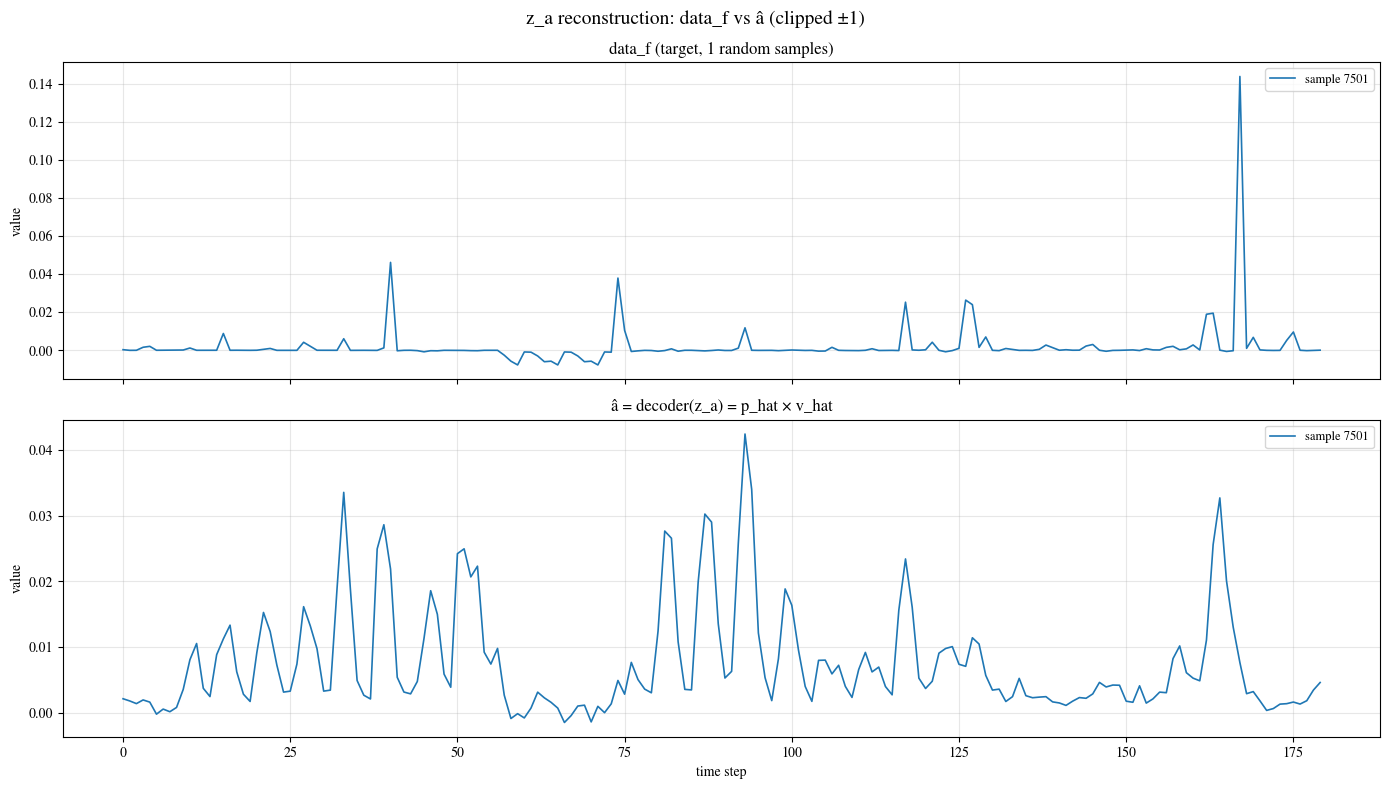

plotted sample indices: [7501]


In [79]:
idx = plot_reconstruction_samples(
    data_f=target,
    a_hat=a_hat,
    N=1,
    clip_value=1,
    seed=np.random.randint(0, 10000),
)
print("plotted sample indices:", idx)
